# Exploration du dataset Longitudinal-CT

**Projet fil rouge : Analyse du phénotype tumoral visible au scanner**

**Objectif du projet :** [à compléter à partir du cahier des charges]

**Objectif de ce notebook :** prendre en main les données, comprendre leur structure, visualiser les images et les lésions, et en déduire les choix de prétraitement.

**Source des données :**
- Longitudinal-CT v2 : DOI [10.57754/FDAT.75kj1-64747](https://doi.org/10.57754/FDAT.75kj1-64747)
- Article associé : DOI [10.1038/s41597-026-07466-y](https://doi.org/10.1038/s41597-026-07466-y)
- Téléchargé depuis le miroir Hugging Face `linghs007/Longitudinal-CT` (51 Go, 300 patients)

**Plan :**
0. Imports et chemins
1. Structure des données
2. Inventaire du dataset
3. Métadonnées
4. Visualisation d'un patient
5. Géométrie des scanners (300 patients)
6. Statistiques sur les lésions (300 patients)
7. Visionneuse interactive
8. Conclusion et choix de prétraitement

## 0. Imports et chemins

In [1]:
import os, glob, json, re
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

ROOT = "data"                       # raccourci vers ~/data/Longitudinal-CT
DATA_DIR = f"{ROOT}/Patient_unzip"
pids = sorted(os.listdir(DATA_DIR))
print(f"Nombre de patients : {len(pids)}")

Nombre de patients : 300


## 1. Structure des données par patient

Chaque patient possède un dossier nommé par un identifiant anonymisé (ex. `0a09c8844b`), qui contient deux sous-dossiers.

**Vocabulaire :**
- **BL** (*Baseline*) : examen de référence, le premier scanner du patient.
- **FU** (*Follow-Up*) : examen de suivi, réalisé plus tard pour voir l'évolution de la lésion.
- **`_00`** : numéro de l'examen ou de la lésion. Certains patients ont des fichiers `_01`, `_02`… (1340 fichiers `.nii.gz` au total pour 300 patients).

### `inputsTr/` : les entrées du modèle (*Tr* = training)

| Fichier | Contenu |
|---|---|
| `<id>_BL_img_00.nii.gz` | Scanner CT 3D de référence (intensités en unités Hounsfield) |
| `<id>_BL_mask_00.nii.gz` | Masque de segmentation de la lésion sur le scanner de référence (même taille que l'image, voxels lésion ≠ 0) |
| `<id>_FU_img_00.nii.gz` | Scanner CT 3D de suivi |
| `<id>_BL_00.json` | Métadonnées de l'examen de référence (à vérifier : date, paramètres d'acquisition…) |
| `<id>_FU_00.json` | Métadonnées de l'examen de suivi (à vérifier) |
| `<id>.csv` | Informations sur le patient et/ou les lésions (à vérifier) |

### `targetsTr/` : la vérité terrain

| Fichier | Contenu |
|---|---|
| `<id>_FU_mask_00.nii.gz` | Masque de la lésion sur le scanner de suivi : c'est ce que le modèle doit prédire |

### Tâche implicite
À partir du scanner de référence, de sa lésion annotée et du scanner de suivi, **retrouver et segmenter la lésion sur le scanner de suivi**. On suit ainsi l'évolution de la tumeur dans le temps.

### Fichiers globaux
- `data_split.json` : répartition des patients entre entraînement et test.
- `README.md` : description officielle du dataset.

**Format NIfTI (`.nii.gz`)** : format standard d'imagerie médicale 3D. Il contient le volume de voxels et un en-tête (dimensions, taille des voxels en mm, orientation). Le `.gz` est une compression lue directement par `nibabel`.

## 2. Inventaire du dataset

In [2]:
# Répartition train / test
split = json.load(open(f"{ROOT}/data_split.json"))
print("Type :", type(split).__name__)
if isinstance(split, dict):
    for k, v in split.items():
        print(f"  {k} : {len(v) if hasattr(v, '__len__') else v}")
else:
    print(split[:3])

Type : dict
  train : 240
  val : 30
  test : 30


In [3]:
# Nombre de fichiers par patient
inv = []
for p in pids:
    files = [os.path.basename(f) for f in glob.glob(f"{DATA_DIR}/{p}/*/*")]
    inv.append({
        "pid": p,
        "n_fichiers": len(files),
        "n_BL_img": sum("_BL_img_" in f for f in files),
        "n_FU_img": sum("_FU_img_" in f for f in files),
        "n_BL_mask": sum("_BL_mask_" in f for f in files),
        "n_FU_mask": sum("_FU_mask_" in f for f in files),
    })
inv = pd.DataFrame(inv)
display(inv.describe())
print("\nNombre d'examens de suivi (FU) par patient :")
print(inv["n_FU_img"].value_counts().sort_index())

,n_fichiers,n_BL_img,n_FU_img,n_BL_mask,n_FU_mask
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,7.693333,1.113333,1.120000,1.113333,1.120000
std,1.800954,0.347695,0.364293,0.347695,0.364293
min,7.000000,1.000000,1.000000,1.000000,1.000000
25%,7.000000,1.000000,1.000000,1.000000,1.000000
50%,7.000000,1.000000,1.000000,1.000000,1.000000
75%,7.000000,1.000000,1.000000,1.000000,1.000000
max,19.000000,3.000000,3.000000,3.000000,3.000000



Nombre d'examens de suivi (FU) par patient :
n_FU_img
1    268
2     28
3      4
Name: count, dtype: int64


### Bilan de l'inventaire
- **Nombre de patients :** 300 
- **Répartition :** le fichier `data_split.json` définit trois ensembles :

| Ensemble | Patients | Part | Usage |
|---|---|---|---|
| `train` | 240 | 80 % | Entraînement du modèle |
| `val` | 30 | 10 % | Réglage des hyperparamètres et choix du meilleur modèle |
| `test` | 30 | 10 % | Évaluation finale, à n'utiliser qu'une seule fois à la fin |

  On réutilise ce découpage officiel tel quel pour que nos résultats soient comparables à ceux de l'article. Le découpage se fait **par patient**, ce qui évite qu'un même patient se retrouve à la fois en entraînement et en test.
- **Nombre d'examens de suivi par patient :**

| Examens FU | Patients | Part |
|---|---|---|
| 1 | 268 | 89 % |
| 2 | 28 | 9 % |
| 3 | 4 | 1 % |

  Soit **336 examens de suivi** au total, chacun avec son masque.
- **Fichiers par patient :** 7 dans le cas standard (scanner, masque et JSON pour le BL ; scanner, masque et JSON pour le FU ; un CSV patient), et jusqu'à 19 pour les patients à 3 suivis. Chaque suivi supplémentaire ajoute un groupe de fichiers indexé `_01`, `_02`.
- **Cohérence :** chaque scanner a bien son masque (autant de `img` que de `mask`, en BL comme en FU) : aucun fichier ne manque.
- Le nombre de scanners BL (334) est très proche, mais pas tout à fait égal, au nombre de FU (336) : certains patients à plusieurs suivis ont plusieurs scanners de référence. Le sens exact des indices `_00`, `_01`, `_02` est [à vérifier dans le README].

**Conséquence :** la grande majorité des patients (89 %) a un seul couple BL → FU. Pour une première version, on peut se limiter aux fichiers `_00`, puis intégrer les suivis supplémentaires comme des couples BL → FU en plus.

## 3. Métadonnées

In [4]:
# Fichiers JSON (un par examen)
rows = []
for f in glob.glob(f"{DATA_DIR}/*/inputsTr/*.json"):
    d = json.load(open(f))
    name = os.path.basename(f)
    d["pid"] = name.split("_")[0]
    d["examen"] = "BL" if "_BL_" in name else "FU"
    rows.append(d)
meta_json = pd.json_normalize(rows)
print(meta_json.shape)
display(meta_json.head())

(668, 7)


,name,points,type,pid,examen,version.major,version.minor
0,Points of interest,"[{'name': '1', 'point': ['178.443711', '317.78...",Multiple points,c9e1074f5b,FU,1,0
1,Points of interest,"[{'name': '1', 'point': ['179.996499', '274.77...",Multiple points,c9e1074f5b,BL,1,0
2,Points of interest,"[{'name': '1', 'point': ['276.233333', '261.95...",Multiple points,31c8f1568c,BL,1,0
3,Points of interest,"[{'name': '1', 'point': ['272.296612', '241.48...",Multiple points,31c8f1568c,FU,1,0
4,Points of interest,"[{'name': '1', 'point': ['374.920042', '211.17...",Multiple points,dc5e819e18,FU,1,0


In [5]:
# Fichiers CSV (un par patient)
dfs = []
for p in pids:
    f = f"{DATA_DIR}/{p}/inputsTr/{p}.csv"
    if os.path.exists(f):
        df = pd.read_csv(f)
        df["pid"] = p
        dfs.append(df)
meta_csv = pd.concat(dfs, ignore_index=True)
print(meta_csv.shape)
display(meta_csv.head())
display(meta_csv.describe(include="all").T)

(4638, 16)


,lesion_id,cog_bl,cog_backpropagated,img_id_bl,cog_propagated,cog_fu,img_id_fu,lesion_type,topology_class,merged_into,volume_bl,volume_fu,target_lesion,use_for_challenge,linking_unclear,pid
0,1,263.976401296545 202.815993359159 92.559293224...,NaN,0,240.98585271862495 178.90587651302837 101.0069...,264.336998706339 189.140362225097 95.293014230...,0,Others,UNCHANGED,NaN,22814.898388,1458.185898,True,True,False,006f52e910
1,1,160.856382978723 205.712765957447 37.822695035461,NaN,0,163.50003049283654 277.09112219027276 40.47643...,164.375 278.763888888889 40.8888888888889,0,Lymph node,UNCHANGED,NaN,644.517334,57.863617,False,True,False,01161aaa0b
2,2,223.740506329114 130.635021097046 26.723628691...,NaN,0,230.15432810760853 190.09753620335977 24.63979...,NaN,0,Lymph node,DISAPPEARING,NaN,270.834412,0.000000,False,True,False,01161aaa0b
3,3,281.334355828221 104.156441717791 28.714723926...,NaN,0,290.3792503980975 152.96963450642397 27.702476...,293.388198757764 158.493788819876 26.052795031...,0,Lymph node,UNCHANGED,NaN,186.270081,129.389477,False,True,False,01161aaa0b
4,4,219.72641509434 232.160377358491 141.5,NaN,1,227.34375053732882 238.88938950024612 140.4772...,NaN,1,Liver,DISAPPEARING,NaN,91.310486,0.000000,False,True,False,01161aaa0b


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
lesion_id,4638.0,NaN,NaN,NaN,17.894998,17.831139,1.0,5.0,12.0,25.0,119.0
cog_bl,4079,4079,263.976401296545 202.815993359159 92.559293224...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cog_backpropagated,527,527,363.962925110501 285.20382156350763 124.643647...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
img_id_bl,4638.0,NaN,NaN,NaN,0.031263,0.178935,0.0,0.0,0.0,0.0,2.0
cog_propagated,3950,3906,511.99993187525985 511.9999318752599 5.6843418...,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cog_fu,3231,3103,336.805748680314 280.772997940003 234.45981395...,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
img_id_fu,4638.0,NaN,NaN,NaN,0.024795,0.164939,0.0,0.0,0.0,0.0,2.0
lesion_type,4638,12,Lung,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
topology_class,4638,4,UNCHANGED,2506,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merged_into,166.0,NaN,NaN,NaN,28.789157,19.798626,3.0,13.0,21.5,50.0,63.0


### Bilan des métadonnées

#### JSON (un par examen) : points d'intérêt
Chaque fichier `<id>_BL_XX.json` / `<id>_FU_XX.json` contient une liste de **points d'intérêt** (`type = "Multiple points"`) : pour chaque lésion (`name` = numéro de la lésion), un point 3D `[x, y, z]` qui la localise dans le scanner. Les champs `version.major` / `version.minor` indiquent la version du format.
Ces points servent probablement de **repères (« prompts »)** pour indiquer au modèle où chercher chaque lésion (système de coordonnées voxel ou mm [à vérifier]).

#### CSV (un par patient) : une ligne par lésion
Au total, **4 638 lésions** pour 300 patients (≈ 15 par patient en moyenne, jusqu'à **119** pour un seul patient).

| Colonne | Signification | Remarques |
|---|---|---|
| `lesion_id` | Numéro de la lésion (1 à 119), correspond au label dans les masques [à vérifier] | |
| `cog_bl` | Centre de gravité de la lésion dans le scanner BL (x, y, z) | 4 079 renseignés : les autres lésions n'existent pas au BL (nouvelles lésions) |
| `cog_fu` | Centre de gravité dans le scanner FU | 3 231 renseignés : absent si la lésion a disparu |
| `cog_propagated` | Position BL **reportée** dans le scanner FU (par recalage) | 3 950 renseignés. ⚠️ 45 lésions ont la valeur aberrante (512, 512, 5,7), en bord d'image : probable échec du recalage |
| `cog_backpropagated` | Position FU reportée dans le scanner BL | 527 renseignés (surtout les nouvelles lésions) |
| `img_id_bl`, `img_id_fu` | Indice de l'examen concerné (0, 1, 2), relié aux fichiers `_00`, `_01`, `_02` | Presque toujours 0 |
| `lesion_type` | Localisation / type de lésion | 12 catégories, la plus fréquente : **poumon** (1 488 lésions) ; aussi ganglions, foie, autres… |
| `topology_class` | Évolution de la lésion entre BL et FU | 4 classes, dont `UNCHANGED` (2 506) et `DISAPPEARING` ; les autres concernent probablement les lésions nouvelles et fusionnées |
| `merged_into` | Numéro de la lésion avec laquelle elle a fusionné | 166 lésions concernées |
| `volume_bl`, `volume_fu` | Volume de la lésion au BL et au FU (probablement en **mm³**) | Médiane ≈ 340 mm³ au BL et ≈ 190 mm³ au FU ; très forte dispersion (de 7 mm³ à plus de 2 millions de mm³) |
| `target_lesion` | Lésion « cible » au sens clinique (suivie en priorité par le radiologue) | 606 lésions (13 %) |
| `use_for_challenge` | Lésion retenue pour la tâche officielle | 4 578 sur 4 638 |
| `linking_unclear` | Correspondance BL ↔ FU incertaine | 135 lésions |

#### Points d'attention
- **Beaucoup de lésions, de tailles très variées.** Le nombre de lésions par patient et leur volume sont très dispersés, avec de nombreuses petites lésions (sous 1 mL).
- **Toutes les lésions ne sont pas présentes aux deux examens :** il y a des lésions nouvelles, disparues et fusionnées.
- **Certaines données sont à filtrer :** les lésions `use_for_challenge = False`, celles dont `linking_unclear = True`, et les 45 `cog_propagated` aberrants.
- Le CSV fournit déjà les **volumes** de chaque lésion, ce qui permet de recouper les volumes calculés à partir des masques (partie 6).

**Tâche confirmée :** pour chaque lésion annotée au BL, on dispose de sa position reportée dans le FU (`cog_propagated`). Le modèle doit **segmenter la lésion correspondante dans le scanner FU**.

## 4. Visualisation d'un patient

On charge les quatre volumes d'un patient (scanner et masque, en BL et en FU). Les volumes sont réorientés de façon standard (RAS) et chargés en `float32` pour limiter la mémoire (≈ 270 Mo par scanner au lieu de 540 Mo en `float64`).

In [6]:
# Charger les volumes d'un patient
pid = "0a09c8844b"

def load(path):
    # Charge un NIfTI, le réoriente de façon standard (RAS) et renvoie (volume, taille des voxels en mm).
    img = nib.as_closest_canonical(nib.load(path))
    return img.get_fdata(dtype=np.float32), img.header.get_zooms()

p_in  = f"{DATA_DIR}/{pid}/inputsTr/{pid}"
p_out = f"{DATA_DIR}/{pid}/targetsTr/{pid}"

bl_img,  bl_sp = load(f"{p_in}_BL_img_00.nii.gz")
bl_mask, _     = load(f"{p_in}_BL_mask_00.nii.gz")
fu_img,  fu_sp = load(f"{p_in}_FU_img_00.nii.gz")
fu_mask, _     = load(f"{p_out}_FU_mask_00.nii.gz")

In [7]:
# Caracteristique de chaque volume

for name, vol, sp in [("BL img", bl_img, bl_sp), ("BL mask", bl_mask, bl_sp),
                      ("FU img", fu_img, fu_sp), ("FU mask", fu_mask, fu_sp)]:
    print(f"{name:8s} | shape {vol.shape} | voxel {tuple(round(float(s), 2) for s in sp)} mm "
          f"| min {vol.min():.0f} max {vol.max():.0f} | valeurs uniques : {len(np.unique(vol)) if 'mask' in name else '-'}")

for name, m, sp in [("BL", bl_mask, bl_sp), ("FU", fu_mask, fu_sp)]:
    vol_ml = (m > 0).sum() * np.prod(sp) / 1000
    print(f"Volume lésion {name} : {vol_ml:.2f} mL")

BL img   | shape (512, 512, 261) | voxel (0.82, 0.82, 3.0) mm | min -1024 max 3071 | valeurs uniques : -
BL mask  | shape (512, 512, 261) | voxel (0.82, 0.82, 3.0) mm | min 0 max 4 | valeurs uniques : 5
FU img   | shape (512, 512, 274) | voxel (0.85, 0.85, 3.0) mm | min -1024 max 3071 | valeurs uniques : -
FU mask  | shape (512, 512, 274) | voxel (0.85, 0.85, 3.0) mm | min 0 max 4 | valeurs uniques : 3
Volume lésion BL : 74.43 mL
Volume lésion FU : 124.32 mL


In [8]:
# Détail par lésion (label)
for name, m, sp in [("BL", bl_mask, bl_sp), ("FU", fu_mask, fu_sp)]:
    labels, counts = np.unique(m[m > 0], return_counts=True)
    vox_ml = np.prod(sp) / 1000
    print(name, {int(l): f"{c * vox_ml:.2f} mL" for l, c in zip(labels, counts)})

BL {1: '18.16 mL', 2: '1.21 mL', 3: '5.41 mL', 4: '49.65 mL'}
FU {3: '7.41 mL', 4: '116.90 mL'}


### Caractéristiques des volumes : patient `0a09c8844b`
- **Taille :** 512 × 512 × 261 coupes (BL) et 512 × 512 × 274 coupes (FU) : les deux examens n'ont **pas le même nombre de coupes**.
- **Taille des voxels :** 0,82 × 0,82 × 3 mm (BL) et 0,85 × 0,85 × 3 mm (FU). Les voxels sont **anisotropes** (3 mm entre les coupes contre < 1 mm dans le plan), et la résolution **diffère entre les deux examens**.
- **Intensités :** de −1024 à 3071 HU, plage standard des scanners CT.
- **Masques :** au BL, 4 labels de lésions (valeurs 1 à 4) ; au FU, seulement 2 labels. Certaines lésions ne sont donc plus annotées au suivi (disparues ou non suivies, à vérifier dans le README).
- **Volume tumoral total :** 74,4 mL au BL contre 124,3 mL au FU, soit **+67 %** : la maladie progresse chez ce patient.

### Visualisation des coupes : patient `0a09c8844b`

Scanner **thoraco-abdomino-pelvien** (du cou au bassin) avec injection de produit de contraste. Les lésions annotées sont en couleur sur l'image.

**Lecture des trois plans de coupe :**
- **Axiale** : tranche horizontale, vue depuis les pieds. Par convention radiologique, la **droite du patient est à gauche de l'image**. On distingue le foie (à gauche), la rate (à droite), les deux reins, la colonne vertébrale (en bas au centre) et l'aorte (juste devant la colonne).
- **Coronale** : tranche verticale vue de face (cou, cœur, foie, rate, bassin).
- **Sagittale** : tranche verticale vue de profil (colonne vertébrale bien visible).

Les arcs en bas des coupes axiales et les lignes verticales des coupes sagittales correspondent à la **table du scanner**, pas au patient.

**Observations :**
- Les lésions se situent dans l'**abdomen, autour de l'aorte, au niveau des reins** (région rétropéritonéale, probablement des ganglions, à confirmer avec les métadonnées).
- Le masque contient **plusieurs lésions**, chacune identifiée par un numéro (label) différent.
- Les coupes BL et FU ne sont **pas exactement au même niveau anatomique** : les deux examens ont été acquis à des dates différentes, sans recalage, et chaque coupe est centrée sur sa propre lésion.
- Visuellement, la lésion autour de l'aorte semble **plus étendue au follow-up** (confirmé par le calcul : le volume total passe de 74,4 à 124,3 mL).

**Conséquences pour la suite :** il faudra gérer plusieurs lésions par patient et tenir compte de l'absence d'alignement entre les deux examens (recalage, ou approche centrée sur la lésion).

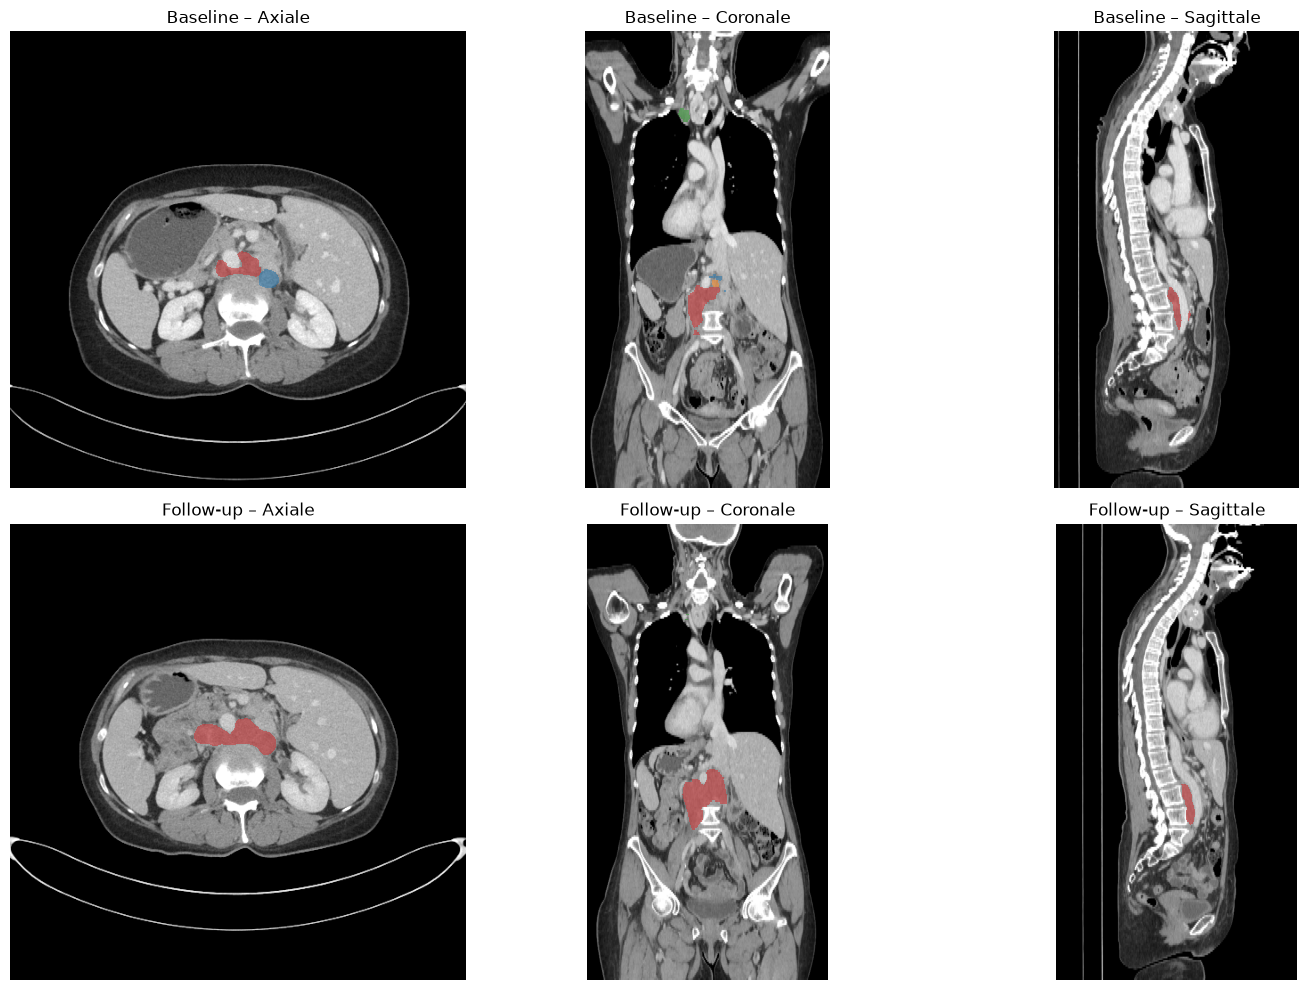

In [9]:
def center(mask):
    """Centre de la lésion (ou du volume si le masque est vide)."""
    idx = np.argwhere(mask > 0)
    return idx.mean(0).astype(int) if len(idx) else np.array(mask.shape) // 2

def show_3views(img, mask, sp, title, axes_row, wl=40, ww=400):
    c = center(mask)
    lo, hi = wl - ww / 2, wl + ww / 2          # fenêtre "tissus mous"
    views = [("Axiale",   img[:, :, c[2]], mask[:, :, c[2]], sp[1] / sp[0]),
             ("Coronale", img[:, c[1], :], mask[:, c[1], :], sp[2] / sp[0]),
             ("Sagittale",img[c[0], :, :], mask[c[0], :, :], sp[2] / sp[1])]
    for ax, (vname, sl, ms, aspect) in zip(axes_row, views):
        ax.imshow(np.rot90(sl), cmap="gray", vmin=lo, vmax=hi, aspect=1 / aspect if vname == "Axiale" else aspect)
        ax.imshow(np.rot90(np.ma.masked_where(ms == 0, ms)), cmap="tab10", vmin=0.5, vmax=10.5,
                  alpha=0.5, interpolation="nearest",
                  aspect=1 / aspect if vname == "Axiale" else aspect)
        ax.set_title(f"{title} – {vname}")
        ax.axis("off")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
show_3views(bl_img, bl_mask, bl_sp, "Baseline", axes[0])
show_3views(fu_img, fu_mask, fu_sp, "Follow-up", axes[1])
plt.tight_layout()
plt.show()

### Distribution des intensités (unités Hounsfield)

Histogramme (échelle logarithmique) des intensités de tous les voxels des scanners BL (bleu) et FU (orange), et des voxels de la lésion au baseline (vert).

**Repères en unités Hounsfield (HU) :**
| Plage (HU) | Correspond à |
|---|---|
| ≈ −1000 | Air (autour du patient, poumons) : pic dominant, car la majorité du volume est de l'air |
| ≈ −100 | Graisse |
| 0 à 100 | Tissus mous (organes, muscles) |
| > 200 | Os et vaisseaux rehaussés par le produit de contraste |

**Observations :**
- Les distributions BL et FU sont **quasiment superposées** : les deux examens ont des intensités comparables, sans normalisation préalable.
- Les voxels de la **lésion** sont concentrés entre **0 et 200 HU (centrés autour de 80 HU)** : c'est du tissu mou, légèrement rehaussé par le produit de contraste.

**Conséquences pour le prétraitement :**
- Une **fenêtre « tissus mous »** (niveau 40, largeur 400) est adaptée à la visualisation des lésions.
- Pour l'entraînement, on pourra **borner les intensités** (environ [−200, 300] HU) puis les normaliser, afin de concentrer le contraste sur la plage utile et d'écarter l'air et l'os.

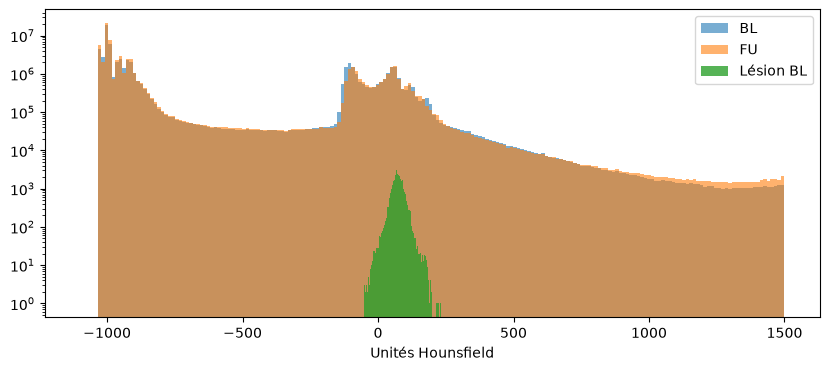

In [10]:
plt.figure(figsize=(10, 4))
plt.hist(bl_img.ravel(), bins=200, range=(-1100, 1500), alpha=0.6, label="BL")
plt.hist(fu_img.ravel(), bins=200, range=(-1100, 1500), alpha=0.6, label="FU")
plt.hist(bl_img[bl_mask > 0], bins=100, alpha=0.8, label="Lésion BL", density=False)
plt.yscale("log"); plt.xlabel("Unités Hounsfield"); plt.legend(); plt.show()

## 5. Géométrie des scanners (300 patients)

On ne lit que les **en-têtes** des fichiers NIfTI (dimensions et taille des voxels), ce qui est quasi instantané.

In [11]:
rows = []
for p in pids:
    for f in glob.glob(f"{DATA_DIR}/{p}/inputsTr/*_img_*.nii.gz"):
        h = nib.load(f).header
        sh = h.get_data_shape()
        sx, sy, sz = h.get_zooms()[:3]
        rows.append({"pid": p, "examen": "BL" if "_BL_" in f else "FU",
                     "nx": sh[0], "ny": sh[1], "nz": sh[2],
                     "sx": float(sx), "sy": float(sy), "sz": float(sz)})
geo = pd.DataFrame(rows)
display(geo.describe())

,nx,ny,nz,sx,sy,sz
count,670.000000,670.0,670.000000,670.000000,670.000000,670.000000
mean,512.428358,512.0,299.141791,0.839831,0.839831,3.021123
std,11.087777,0.0,233.199061,0.110295,0.110294,0.868231
min,512.000000,512.0,28.000000,0.429688,0.429688,0.625000
25%,512.000000,512.0,214.250000,0.781438,0.781438,3.000000
50%,512.000000,512.0,265.500000,0.847656,0.847656,3.000000
75%,512.000000,512.0,294.000000,0.917969,0.917969,3.000000
max,799.000000,512.0,2471.000000,1.523438,1.523438,7.400229


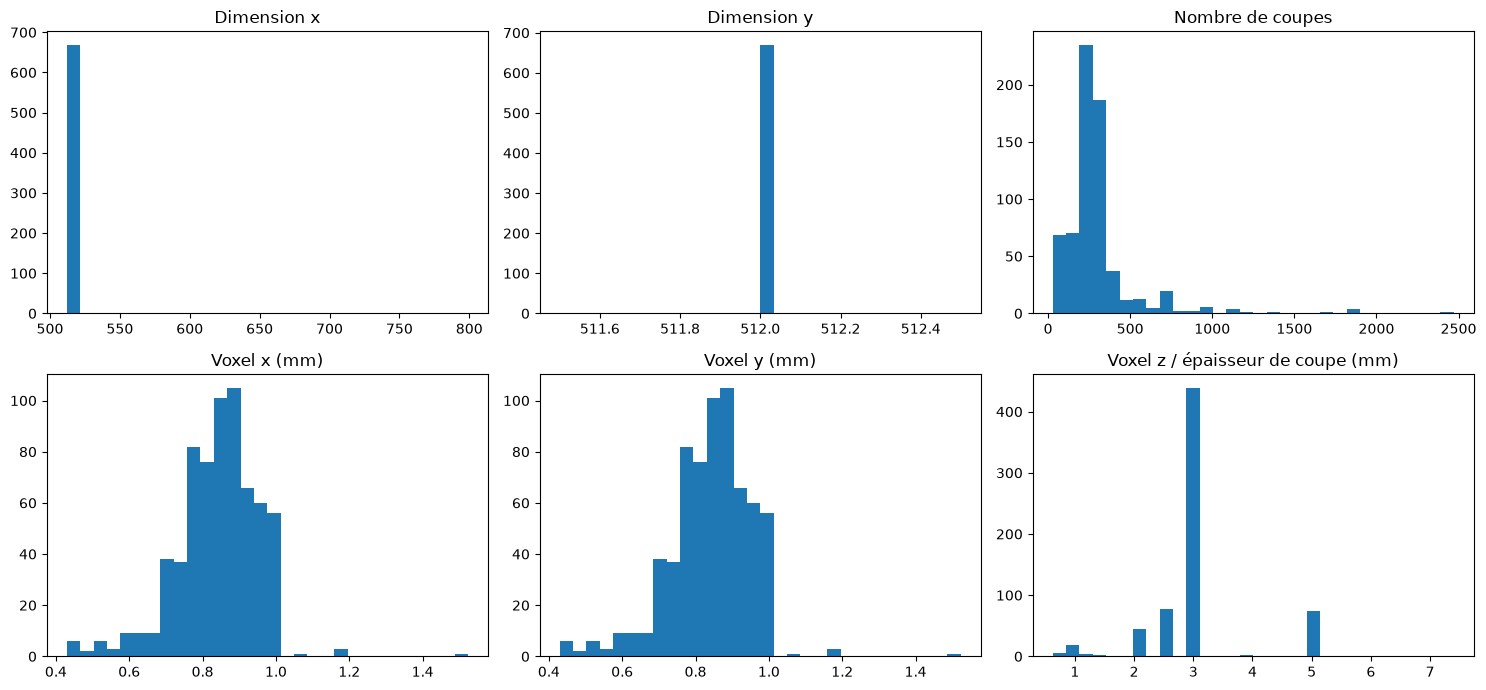

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col, lab in zip(axes.ravel(), ["nx", "ny", "nz", "sx", "sy", "sz"],
                        ["Dimension x", "Dimension y", "Nombre de coupes",
                         "Voxel x (mm)", "Voxel y (mm)", "Voxel z / épaisseur de coupe (mm)"]):
    ax.hist(geo[col], bins=30)
    ax.set_title(lab)
plt.tight_layout(); plt.show()

### Bilan de la géométrie (670 scanners : 334 BL + 336 FU)

| Paramètre | Min | Q1 | Médiane | Q3 | Max | Commentaire |
|---|---|---|---|---|---|---|
| Taille x (voxels) | 512 | 512 | 512 | 512 | 799 | Un **seul** scanner fait exception (799) ; tous les autres sont en 512 |
| Taille y (voxels) | 512 | 512 | 512 | 512 | 512 | Identique pour tous les scanners |
| Nombre de coupes (z) | 28 | 214 | 266 | 294 | 2 471 | La moitié des scanners a entre 214 et 294 coupes ; quelques volumes très longs |
| Voxel dans le plan (mm) | 0,43 | 0,78 | 0,85 | 0,92 | 1,52 | x et y toujours identiques (pixels carrés) |
| Épaisseur de coupe (mm) | 0,625 | 3 | 3 | 3 | 7,4 | **Au moins 50 % des scanners sont à exactement 3 mm** ; les autres vont de 0,625 à 7,4 mm |

**Observations :**
- **Les voxels sont fortement anisotropes :** 0,85 mm dans le plan contre 3 mm entre les coupes (médianes), soit un rapport d'environ 1 à 3,5. La résolution est bien meilleure dans le plan axial que dans la hauteur.
- **La résolution est hétérogène :** l'épaisseur de coupe va de 0,625 à 7,4 mm selon les examens, avec des valeurs discrètes (2 ; 2,5 ; 3 ; 5 mm…) liées aux protocoles des différents hôpitaux et scanners. Elle peut différer entre le BL et le FU d'un même patient.
- Les scanners avec un très grand nombre de coupes (jusqu'à 2 471) correspondent à des **coupes fines**, et donc à des volumes très lourds en mémoire.
- Avec 3 mm entre les coupes, les **petites lésions** (quelques mm) n'apparaissent que sur 1 à 3 coupes, ce qui les rend difficiles à segmenter.

**Conséquence : un rééchantillonnage est indispensable** pour que tous les volumes aient la même résolution. Deux options :
1. **Rééchantillonner à la résolution médiane** (**0,85 × 0,85 × 3 mm**), comme le fait par exemple nnU-Net. On conserve la résolution native de la majorité des examens sans créer d'information artificielle, mais les voxels restent anisotropes.
2. **Rééchantillonner en isotrope** (ex. 1 × 1 × 1 mm). C'est plus simple pour les réseaux 3D et pour comparer les directions, mais le nombre de coupes est multiplié par 3 pour les examens à 3 mm, ce qui alourdit la mémoire et revient à interpoler des coupes qui n'existent pas.

**Choix retenu :** [à décider, ex. option 1 pour une première version]

## 6. Statistiques sur les lésions (300 patients)

On lit tous les masques pour calculer le volume de chaque lésion. Le calcul prend quelques minutes, puis le résultat est sauvegardé dans `data/lesions_stats.csv` pour ne pas avoir à le refaire.

In [13]:
def label_volumes(path):
    # Renvoie {numéro de lésion: volume en mL} pour un fichier masque.
    img = nib.load(path)
    m = np.asanyarray(img.dataobj)
    nz = m[m > 0]
    if nz.dtype.kind == "f":
        nz = np.round(nz).astype(np.int32)
    voxel_ml = np.prod(img.header.get_zooms()[:3]) / 1000
    labels, counts = np.unique(nz, return_counts=True)
    return {int(l): float(c * voxel_ml) for l, c in zip(labels, counts)}

STATS_CSV = f"{ROOT}/lesions_stats.csv"
if os.path.exists(STATS_CSV):
    les = pd.read_csv(STATS_CSV)
else:
    rows = []
    for i, p in enumerate(pids):
        for f in glob.glob(f"{DATA_DIR}/{p}/*/{p}_*_mask_*.nii.gz"):
            exam, idx = re.search(r"_(BL|FU)_mask_(\d+)", os.path.basename(f)).groups()
            for lab, vol in label_volumes(f).items():
                rows.append({"pid": p, "examen": exam, "idx": int(idx), "label": lab, "vol_ml": vol})
        if i % 25 == 0:
            print(f"{i}/{len(pids)}")
    les = pd.DataFrame(rows)
    les.to_csv(STATS_CSV, index=False)
display(les.head())

,pid,examen,idx,label,vol_ml
0,006f52e910,BL,0,1,22.814898
1,006f52e910,FU,0,1,1.458186
2,01161aaa0b,BL,1,4,0.091310
3,01161aaa0b,BL,1,5,0.446215
4,01161aaa0b,BL,1,9,0.267040


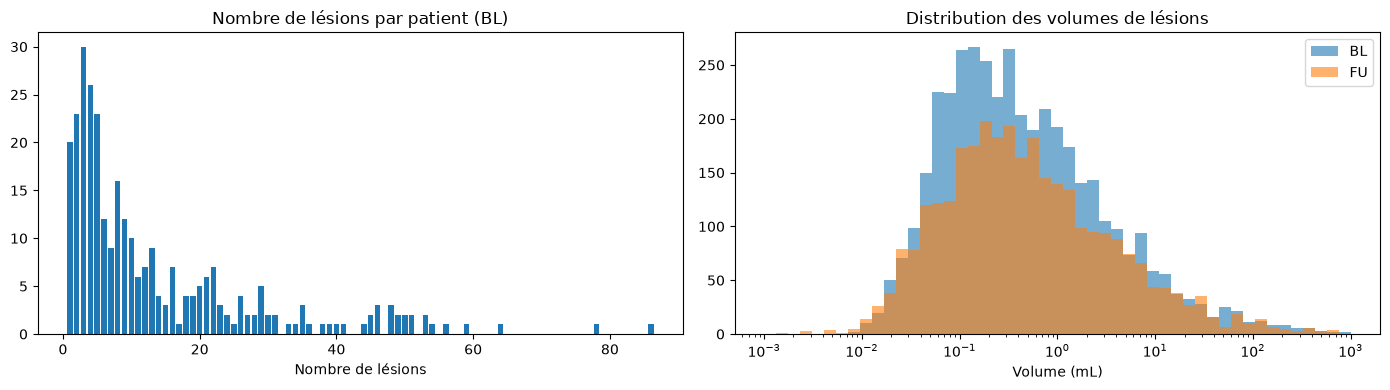

         count      mean        std       min       25%       50%       75%  \
examen                                                                        
BL      4079.0  7.264959  63.291927  0.007202  0.109999  0.340732  1.434437   
FU      3103.0  8.938254  72.359377  0.001575  0.118655  0.382768  1.617002   

                max  
examen               
BL      2349.590576  
FU      1892.169365  


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

n_les = les[les.examen == "BL"].groupby("pid")["label"].nunique()
axes[0].hist(n_les, bins=range(1, n_les.max() + 2), align="left", rwidth=0.8)
axes[0].set_title("Nombre de lésions par patient (BL)")
axes[0].set_xlabel("Nombre de lésions")

for ex in ["BL", "FU"]:
    axes[1].hist(les[les.examen == ex]["vol_ml"], bins=np.logspace(-3, 3, 50), alpha=0.6, label=ex)
axes[1].set_xscale("log"); axes[1].set_xlabel("Volume (mL)")
axes[1].set_title("Distribution des volumes de lésions"); axes[1].legend()
plt.tight_layout(); plt.show()

print(les.groupby("examen")["vol_ml"].describe())

**Évolution BL → FU.** Hypothèse : un même numéro de label désigne la même lésion en BL et en FU (à vérifier dans le README).

statut
Disparue                1535
Régression (< -20 %)    1287
Croissance (> +20 %)     946
Nouvelle                 559
Stable                   311
Name: count, dtype: int64


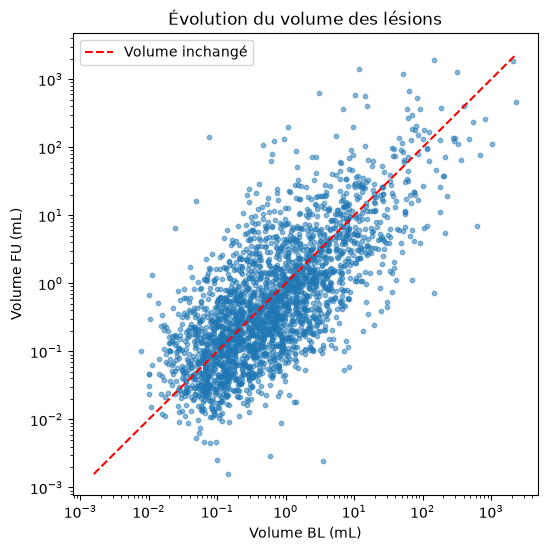

In [15]:
bl = les[les.examen == "BL"].groupby(["pid", "label"])["vol_ml"].sum().rename("vol_bl").reset_index()
fu = les[les.examen == "FU"].rename(columns={"vol_ml": "vol_fu"})[["pid", "idx", "label", "vol_fu"]]
pairs = bl.merge(fu, on=["pid", "label"], how="outer").fillna({"vol_bl": 0, "vol_fu": 0})

def statut(r):
    if r.vol_bl == 0: return "Nouvelle"
    if r.vol_fu == 0: return "Disparue"
    ratio = r.vol_fu / r.vol_bl
    if ratio > 1.2: return "Croissance (> +20 %)"
    if ratio < 0.8: return "Régression (< -20 %)"
    return "Stable"
pairs["statut"] = pairs.apply(statut, axis=1)
print(pairs["statut"].value_counts())

both = pairs[(pairs.vol_bl > 0) & (pairs.vol_fu > 0)]
plt.figure(figsize=(6, 6))
plt.scatter(both.vol_bl, both.vol_fu, s=10, alpha=0.5)
lim = [both[["vol_bl", "vol_fu"]].min().min(), both[["vol_bl", "vol_fu"]].max().max()]
plt.plot(lim, lim, "r--", label="Volume inchangé")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Volume BL (mL)"); plt.ylabel("Volume FU (mL)")
plt.title("Évolution du volume des lésions"); plt.legend(); plt.show()

### Bilan des lésions

#### Cohérence masques ↔ métadonnées ✅
- **4 079 lésions au BL** dans les masques : exactement le nombre de `volume_bl` renseignés dans le CSV.
- **Volume médian au BL : 0,341 mL**, identique au `volume_bl` médian du CSV (340,7 mm³).
- **Total : 4 638 lésions**, comme dans le CSV.

On en déduit que **les labels des masques correspondent bien aux `lesion_id` du CSV**, et que les volumes du CSV sont exprimés en **mm³**.

#### Nombre de lésions par patient (BL)
- Très variable : la majorité des patients a **entre 1 et 10 lésions** (mode ≈ 3), mais la distribution a une longue traîne, jusqu'à **≈ 86 lésions** pour un seul patient. (C'est possible ?)
- Certains patients sont donc des cas **multi-métastatiques** très lourds, d'autres n'ont que quelques lésions.

#### Volumes des lésions

| | Nombre | Min | Q1 | Médiane | Q3 | Max | Moyenne |
|---|---|---|---|---|---|---|---|
| **BL** | 4 079 | 0,007 mL | 0,11 mL | **0,34 mL** | 1,43 mL | 2 350 mL | 7,3 mL |
| **FU** | 3 103 | 0,002 mL | 0,12 mL | **0,38 mL** | 1,62 mL | 1 892 mL | 8,9 mL |

- La distribution est **log-normale** : les volumes s'étalent sur **6 ordres de grandeur** (de quelques mm³ à plus de 2 litres).
- **La grande majorité des lésions est petite :** 75 % font moins de 1,5 mL, soit une sphère d'environ 14 mm de diamètre, et 25 % font moins de 0,11 mL (environ 6 mm de diamètre).
- La moyenne (7 à 9 mL) est **20 fois supérieure à la médiane** : quelques très grosses lésions tirent la moyenne vers le haut.
- ⚠️ **Valeurs extrêmes à vérifier :** des lésions de plus de 1 litre, et d'autres de seulement 1 à 2 voxels (probable bruit d'annotation).

#### Évolution BL → FU (4 638 lésions)

| Statut | Lésions | Part |
|---|---|---|
| Disparue | 1 535 | 33 % |
| Régression (< −20 %) | 1 287 | 28 % |
| Croissance (> +20 %) | 946 | 20 % |
| Nouvelle | 559 | 12 % |
| Stable (± 20 %) | 311 | 7 % |

- Parmi les **2 544 lésions présentes aux deux examens**, 51 % régressent, 37 % grossissent et seulement 12 % restent stables. Les lésions évoluent donc fortement entre les deux examens, probablement sous l'effet des traitements.
- Sur le nuage de points, les volumes BL et FU sont **corrélés** (le nuage suit la diagonale), mais avec une **forte dispersion**, et un peu plus de points sous la diagonale (régression).
- Le seuil de ± 20 % est arbitraire. Pour les petites lésions, une variation de volume de cet ordre peut venir de l'imprécision de la segmentation (coupes de 3 mm) plutôt que d'une vraie évolution.
- Une partie des lésions classées « disparues » ont en réalité **fusionné** avec une autre lésion (`merged_into`, 166 cas). Pour une classification exacte, il faudra s'appuyer sur la colonne `topology_class` du CSV.

#### Conséquences pour la suite
- **Petites lésions majoritaires :** elles sont difficiles à segmenter, surtout avec des coupes de 3 mm. Il faudra des patchs centrés sur les lésions et une perte adaptée (ex. Dice + entropie croisée).
- **Évaluation :** le score de Dice est instable sur les petites lésions. Il faudra analyser les performances **par taille de lésion**.
- **Lésions disparues ou nouvelles :** le modèle doit savoir prédire un masque **vide** quand une lésion a disparu. Les lésions nouvelles, absentes au BL, ne sont pas couvertes par la tâche principale.
- **Grande variabilité entre patients**, de 1 à plus de 80 lésions : il faudra en tenir compte dans l'échantillonnage pendant l'entraînement, pour ne pas surreprésenter les patients multi-métastatiques.

## 7. Visionneuse interactive

Le curseur permet de parcourir les coupes axiales du patient chargé en partie 4. Il démarre au centre de la lésion. Utile pour vérifier l'étendue des lésions et repérer les cas atypiques.

Nécessite `ipywidgets` (dans le terminal : `pip install ipywidgets`).

In [16]:
import ipywidgets as w

def viewer(img, mask, title, wl=40, ww=400):
    def show(z):
        plt.figure(figsize=(6, 6))
        plt.imshow(np.rot90(img[:, :, z]), cmap="gray", vmin=wl - ww / 2, vmax=wl + ww / 2)
        ms = mask[:, :, z]
        plt.imshow(np.rot90(np.ma.masked_where(ms == 0, ms)), cmap="tab10",
                   vmin=0.5, vmax=10.5, alpha=0.5, interpolation="nearest")
        plt.title(f"{title} – coupe {z}/{img.shape[2] - 1}")
        plt.axis("off"); plt.show()
    w.interact(show, z=w.IntSlider(value=int(center(mask)[2]), min=0,
                                   max=img.shape[2] - 1, continuous_update=False))

viewer(bl_img, bl_mask, "Baseline")

interactive(children=(IntSlider(value=114, continuous_update=False, description='z', max=260), Output()), _dom…

In [17]:
viewer(fu_img, fu_mask, "Follow-up")

interactive(children=(IntSlider(value=117, continuous_update=False, description='z', max=273), Output()), _dom…

## 8. Conclusion et choix de prétraitement

### Ce qu'on retient

**Le dataset**
- **300 patients**, répartis selon le découpage officiel en **240 train / 30 val / 30 test** (par patient).
- Chaque patient a un scanner de référence (BL) et au moins un scanner de suivi (FU) : 89 % n'ont qu'un suivi, 11 % en ont 2 ou 3 (336 examens FU au total).
- Les données sont **complètes et cohérentes** : chaque scanner a son masque, et les volumes calculés à partir des masques correspondent exactement à ceux du CSV (labels des masques = `lesion_id`).
- Les métadonnées CSV décrivent **chaque lésion** : type (12 catégories, surtout poumon), évolution (`topology_class`), volumes, centres de gravité au BL et au FU, et position reportée dans le FU (`cog_propagated`).

**Les images**
- Scanners thoraco-abdomino-pelviens injectés, de **512 × 512** pixels dans le plan, avec en médiane **266 coupes**.
- **Résolution hétérogène et anisotrope** : voxels médians de **0,85 × 0,85 × 3 mm**, avec une épaisseur de coupe allant de 0,625 à 7,4 mm selon les examens.
- Les examens BL et FU **ne sont pas recalés** (position, champ de vue et nombre de coupes différents).
- Les lésions sont du **tissu mou rehaussé (≈ 0 à 200 HU)**.

**Les lésions**
- **4 638 lésions**, très inégalement réparties : de 1 à plus de 80 par patient (mode ≈ 3).
- **Majoritairement petites** : volume médian de 0,34 mL, 75 % sous 1,5 mL, mais une étendue de plus de 6 ordres de grandeur (de quelques mm³ à 2,3 L).
- **Évolution BL → FU très variable** : 33 % disparaissent, 28 % régressent, 20 % grossissent, 12 % apparaissent et seulement 7 % restent stables.
- Certains cas sont particuliers : lésions fusionnées (166), correspondance BL ↔ FU incertaine (135), lésions exclues de la tâche officielle (60) et 45 positions reportées aberrantes.


### Points de vigilance pour la modélisation
- **Les petites lésions sont majoritaires**, et donc difficiles à segmenter avec des coupes de 3 mm. Il faudra utiliser une perte adaptée (Dice + entropie croisée) et évaluer les performances **par taille de lésion**.
- **Le modèle doit gérer les lésions disparues**, en prédisant un masque vide.
- **La variabilité entre patients** (de 1 à plus de 80 lésions) impose un échantillonnage équilibré, pour ne pas surreprésenter les patients multi-métastatiques.
- **Les ressources sont limitées** : avec environ 7,6 Go de RAM sous WSL, on ne peut pas charger beaucoup de scanners complets à la fois, d'où l'intérêt de travailler par patchs.

